In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load COVID-19 dataset from Our World in Data
url = "https://catalog.ourworldindata.org/garden/covid/latest/compact/compact.csv"
covid_df = pd.read_csv(url)

# Parse date column and filter for year 2021 and selected countries
covid_df["date"] = pd.to_datetime(covid_df["date"])

countries_2021 = [
    "Greece",
    "Italy",
    "Germany",
    "France",
    "Spain",
    "United States",
    "Japan",
    "Brazil",
]

selected_columns = [
    "continent",
    "country",
    "date",
    "population",
    "new_cases",
    "new_deaths",
    "total_cases",
    "total_deaths",
    "people_vaccinated",
    "total_vaccinations_per_hundred",
    "gdp_per_capita",
]

covid_2021 = covid_df[
    (covid_df["date"].dt.year == 2021) & (covid_df["country"].isin(countries_2021))
][selected_columns].copy()

# Sort by country and date before time-based operations and interpolation
covid_2021 = covid_2021.sort_values(["country", "date"]).reset_index(drop=True)
print("Filtered dataset shape:", covid_2021.shape)

Filtered dataset shape: (2920, 11)


In [9]:
print("Missing values before cleaning:\n", covid_2021.isnull().sum())
print("\nDuplicate rows:", covid_2021.duplicated().sum())

# Remove exact duplicate rows if any exist
covid_2021 = covid_2021.drop_duplicates()

# Fill missing daily new cases and deaths with 0
covid_2021["new_cases"] = covid_2021["new_cases"].fillna(0)
covid_2021["new_deaths"] = covid_2021["new_deaths"].fillna(0)

# Inspect negative daily values (often caused by reporting adjustments in public datasets)
negative_cases = (covid_2021["new_cases"] < 0).sum()
negative_deaths = (covid_2021["new_deaths"] < 0).sum()
print(
    f"\nNegative new_cases: {negative_cases}, Negative new_deaths: {negative_deaths}"
)

# Interpolate vaccination series within each country separately
covid_2021["people_vaccinated"] = covid_2021.groupby("country")[
    "people_vaccinated"
].transform(lambda s: s.interpolate(method="linear").ffill().bfill())

covid_2021["total_vaccinations_per_hundred"] = (
    covid_2021.groupby("country")["total_vaccinations_per_hundred"]
    .transform(lambda s: s.interpolate(method="linear").ffill().bfill())
)

Missing values before cleaning:
 continent                           0
country                             0
date                                0
population                          0
new_cases                           1
new_deaths                          0
total_cases                         0
total_deaths                        0
people_vaccinated                 221
total_vaccinations_per_hundred    223
gdp_per_capita                      0
dtype: int64

Duplicate rows: 0

Negative new_cases: 0, Negative new_deaths: 0


In [10]:
# Daily new cases and deaths summary per country
daily_stats = covid_2021.groupby("country").agg(
    avg_daily_new_cases=("new_cases", "mean"),
    max_daily_new_cases=("new_cases", "max"),
    avg_daily_new_deaths=("new_deaths", "mean"),
    max_daily_new_deaths=("new_deaths", "max"),
)
print("Daily new cases & deaths summary per country:\n", daily_stats.round(2))

# Country with highest raw cumulative totals in the sample
most_affected_raw = (
    covid_2021.groupby("country")[["total_cases", "total_deaths"]]
    .max()
    .idxmax()
)
print("\nHighest raw cumulative totals among selected countries:\n", most_affected_raw)

# Normalize cumulative cases and deaths per 100,000 inhabitants
covid_2021["cases_per_100k"] = (
    covid_2021["total_cases"] / covid_2021["population"]
) * 100000
covid_2021["deaths_per_100k"] = (
    covid_2021["total_deaths"] / covid_2021["population"]
) * 100000

most_affected_normalized = (
    covid_2021.groupby("country")[["cases_per_100k", "deaths_per_100k"]]
    .max()
    .sort_values(by="cases_per_100k", ascending=False)
)
print("\nNormalized metrics (per 100k):\n", most_affected_normalized.round(2))

# Vaccination metrics by country and continent
greatest_vaccinations_country = (
    covid_2021.groupby("country")["total_vaccinations_per_hundred"]
    .max()
    .idxmax()
)
avg_vaccinations_per_continent = covid_2021.groupby("continent")[
    "total_vaccinations_per_hundred"
].mean()

print("\nHighest vaccinations per hundred country:", greatest_vaccinations_country)
print(
    "\nAverage vaccinations per hundred by continent:\n",
    avg_vaccinations_per_continent.round(2),
)

Daily new cases & deaths summary per country:
                avg_daily_new_cases  max_daily_new_cases  avg_daily_new_deaths  \
country                                                                         
Brazil                    40276.32             150106.0               1167.50   
France                    17456.62             519740.0                166.11   
Germany                   14668.12             403348.0                193.65   
Greece                     2590.12              46907.0                 43.35   
Italy                     10678.74             127000.0                174.36   
Japan                      4119.13              26050.0                 41.04   
Spain                     11453.67             491046.0                102.22   
United States             93032.06             474309.0               1279.59   

               max_daily_new_deaths  
country                              
Brazil                       4249.0  
France                      

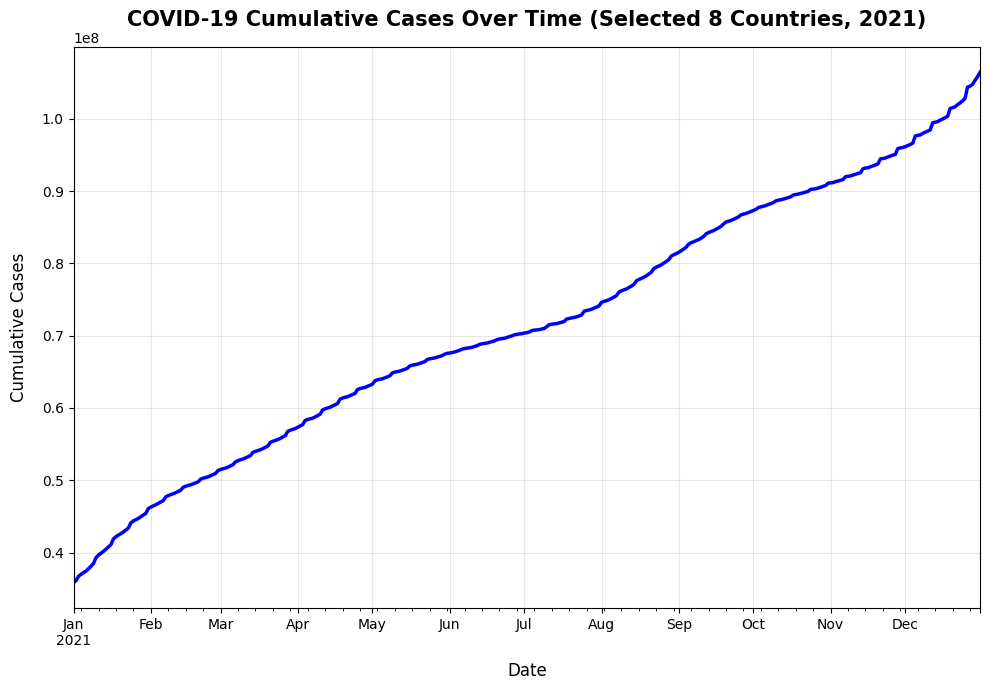

In [11]:
total_cases_by_date = covid_2021.groupby("date")["total_cases"].sum()

total_cases_by_date.plot(
    kind="line",
    figsize=(10, 7),
    color="blue",
    linewidth=2.5,
    linestyle="-",
)
plt.title(
    "COVID-19 Cumulative Cases Over Time (Selected 8 Countries, 2021)",
    fontsize=15,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12, labelpad=10)
plt.ylabel("Cumulative Cases", fontsize=12, labelpad=10)
plt.grid(linestyle="-", alpha=0.3)
plt.tight_layout()
plt.show()

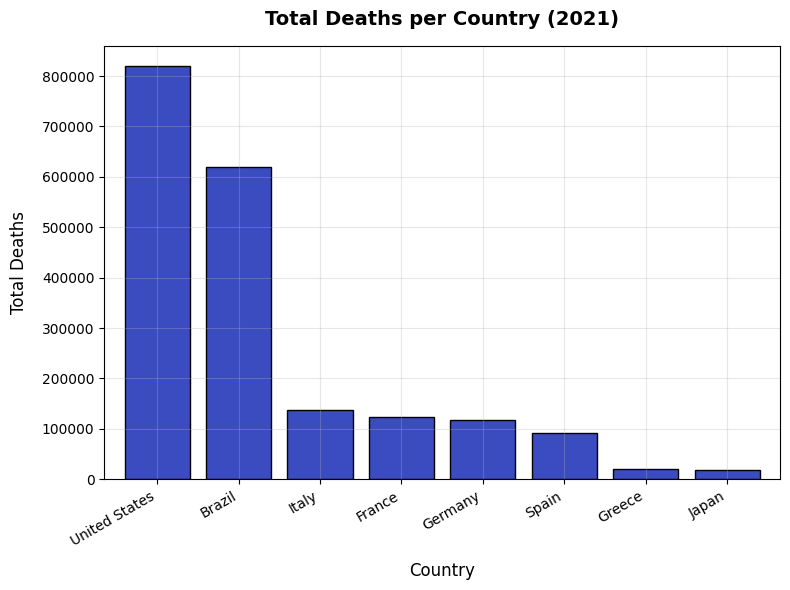

In [12]:
total_deaths_by_country = (
    covid_2021.groupby("country")["total_deaths"]
    .max()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 6))
total_deaths_by_country.plot(
    kind="bar",
    colormap="coolwarm",
    edgecolor="black",
    width=0.8,
)
plt.title(
    "Total Deaths per Country (2021)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Country", fontsize=12, labelpad=10)
plt.ylabel("Total Deaths", fontsize=12, labelpad=10)
plt.xticks(rotation=30, ha="right")
plt.grid(linestyle="-", alpha=0.3)
plt.tight_layout()
plt.show()

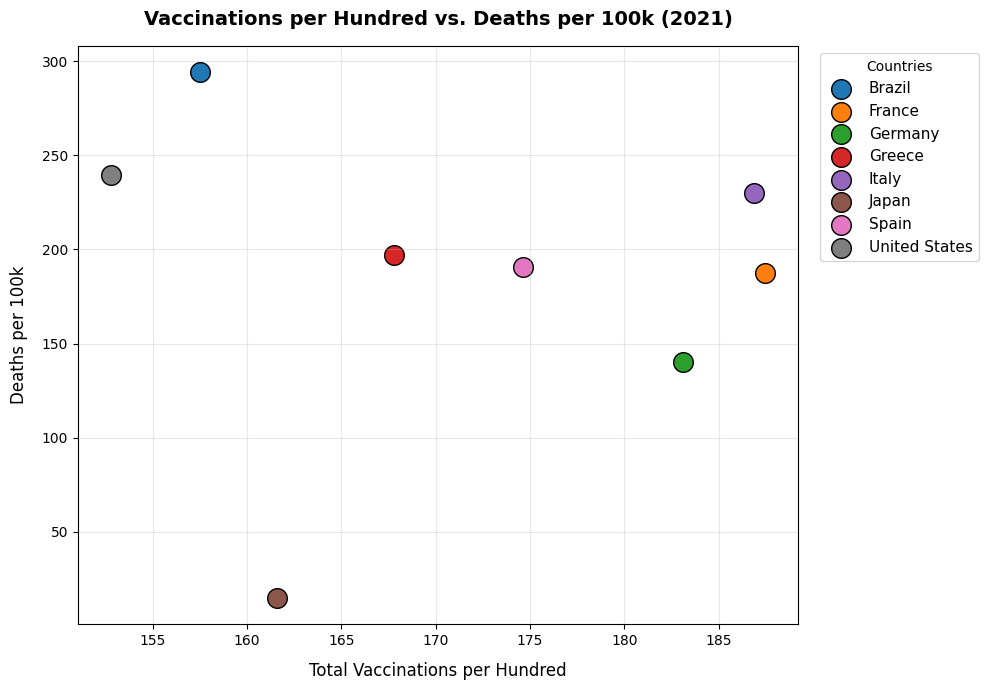

In [13]:
vaccinations_vs_deaths = covid_2021.groupby("country")[
    ["total_vaccinations_per_hundred", "deaths_per_100k"]
].max()

plt.figure(figsize=(10, 7))
for country, row in vaccinations_vs_deaths.iterrows():
  plt.scatter(
      row["total_vaccinations_per_hundred"],
      row["deaths_per_100k"],
      s=200,
      edgecolors="black",
      label=country,
  )

plt.title(
    "Vaccinations per Hundred vs. Deaths per 100k (2021)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Total Vaccinations per Hundred", fontsize=12, labelpad=10)
plt.ylabel("Deaths per 100k", fontsize=12, labelpad=10)
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=11,
    title="Countries",
    frameon=True,
)
plt.grid(linestyle="-", alpha=0.3)
plt.tight_layout()
plt.show()

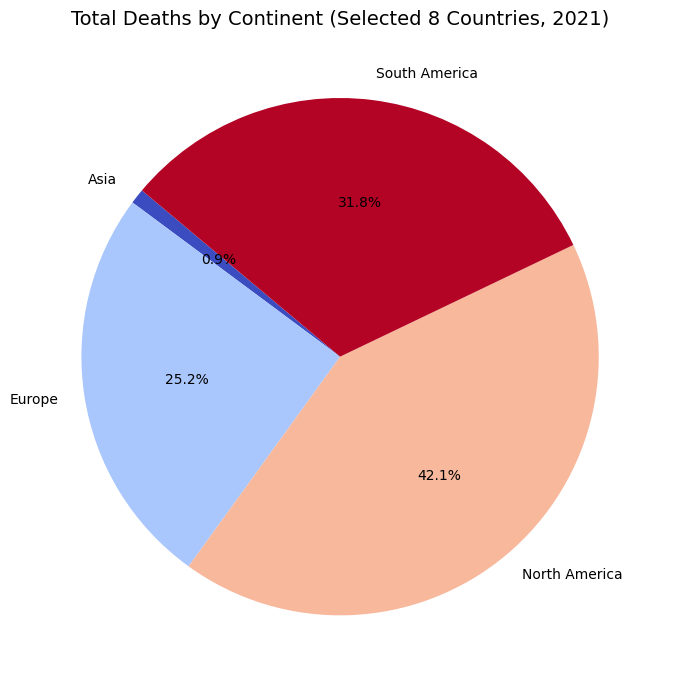

In [14]:
country_max_deaths = (
    covid_2021.groupby(["continent", "country"])["total_deaths"]
    .max()
    .reset_index()
)
deaths_by_continent = country_max_deaths.groupby("continent")[
    "total_deaths"
].sum()

deaths_by_continent.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7, 7),
    startangle=140,
    colormap="coolwarm",
)
plt.title(
    "Total Deaths by Continent (Selected 8 Countries, 2021)", fontsize=14
)
plt.ylabel("")
plt.tight_layout()
plt.show()

### Summary of Findings (2021 Sample)
Based on the 2021 COVID-19 dataset for the eight selected countries, cumulative cases increased steadily over the course of the year. In raw numbers, the United States and Brazil recorded the highest total cases and deaths, largely influenced by population size. Normalizing by population (per 100,000 inhabitants) shifts how countries compare relative to their size, and higher vaccination coverage generally aligns with lower deaths per 100k within this sample.